In [1]:
import pandas as pd

# Charger le fichier CSV
df = pd.read_csv("../data/raw/retail_store_sales.csv")

# Afficher les 5 premières lignes
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [5]:
# Afficher le nombre de lignes et de colonnes
print("la dimension de mon dataset:", df.shape)

# Afficher les informations sur les colonnes
df.info()

# Compter les valeurs manquantes par colonne
print("\nValeurs manquantes :")
print(df.isna().sum())

# Compter les lignes en double
print("le nombre de lignes en double:", df.duplicated().sum())

la dimension de mon dataset: (12575, 11)
<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.1+ MB

Valeurs manquantes :
Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent       

In [6]:
# Calculer le nombre de valeurs manquantes par colonne
missing_values = df.isna().sum()

# Calculer le pourcentage de valeurs manquantes
missing_percentage = (df.isna().sum() / len(df)) * 100

# Créer un tableau récapitulatif
missing_table = pd.DataFrame({
    "Valeurs manquantes": missing_values,
    "Pourcentage (%)": missing_percentage
})

# Afficher uniquement les colonnes qui ont des valeurs manquantes
missing_table[missing_table["Valeurs manquantes"] > 0]

,Valeurs manquantes,Pourcentage (%)
Item,1213,9.646123
Price Per Unit,609,4.842942
Quantity,604,4.803181
Total Spent,604,4.803181
Discount Applied,4199,33.391650


In [7]:
# Vérifier si des identifiants de transaction sont répétés
df["Transaction ID"].duplicated().sum()

np.int64(0)

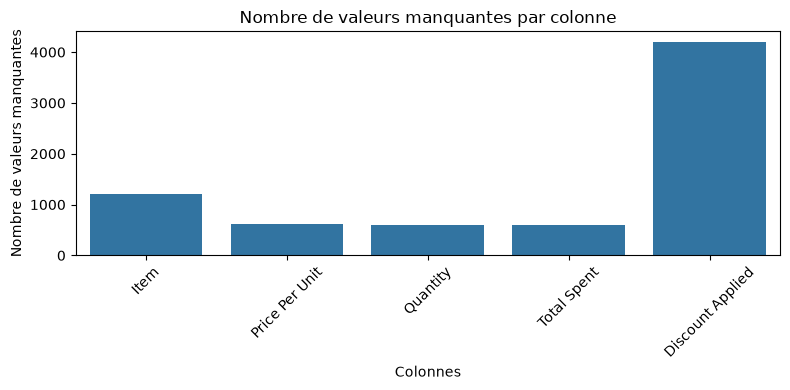

<Figure size 640x480 with 0 Axes>

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculer les valeurs manquantes
missing = df.isna().sum()

# Garder uniquement les colonnes concernées
missing = missing[missing > 0]

# Créer un graphique
plt.figure(figsize=(8, 4))
sns.barplot(x=missing.index, y=missing.values)

plt.title("Nombre de valeurs manquantes par colonne")
plt.xlabel("Colonnes")
plt.ylabel("Nombre de valeurs manquantes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.savefig("../figures/valeurs_manquantes.png")


In [16]:
# Vérifier le nombre de lignes dupliquées
print("Nombre de lignes en double :", df.duplicated().sum())

# Vérifier les identifiants de transaction dupliqués
print("Nombre de transactions répétées :",
      df["Transaction ID"].duplicated().sum())

Nombre de lignes en double : 0
Nombre de transactions répétées : 0


In [19]:
# Colonnes numériques à analyser
colonnes = ["Price Per Unit", "Quantity", "Total Spent"]

for colonne in colonnes:
    # Calculer le premier et le troisième quartile
    Q1 = df[colonne].quantile(0.25)
    Q3 = df[colonne].quantile(0.75)

    # Calculer l'écart interquartile
    IQR = Q3 - Q1

    # Calculer les limites
    borne_basse = Q1 - 1.5 * IQR
    borne_haute = Q3 + 1.5 * IQR

    # Identifier les valeurs aberrantes
    valeurs_aberrantes = df[
        (df[colonne] < borne_basse) |
        (df[colonne] > borne_haute)
    ]

    print(f"\nColonne : {colonne}")
    print("Nombre de valeurs aberrantes :", len(valeurs_aberrantes))


Colonne : Price Per Unit
Nombre de valeurs aberrantes : 0

Colonne : Quantity
Nombre de valeurs aberrantes : 0

Colonne : Total Spent
Nombre de valeurs aberrantes : 60
